# Experimento 03 - Análise Temática de Diálogos

In [29]:
#pip install -r requirements.txt2

In [30]:
from langchain_openai import AzureChatOpenAI
from langchain_openai.embeddings import AzureOpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from sklearn.metrics.pairwise import cosine_similarity

In [31]:
load_dotenv()

llm = AzureChatOpenAI(
    model="gpt-4o", 
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

system_prompt = """
Você é um assistente inteligente que vai construir uma conversa entre duas personas. Considere que a conversa pode ser natural (pode ser como num formato de podcast). Seu trabalho e gerar uma conversa extensa que começa com tópicos relacionados à {topic_1}, mas que gradualmente se move para tópicos relacionados a {topic_2}.

Siga o seguinte padrão para a conversa:

Persona 1: [fala algo que pode ser relacionado a {topic_1}]
Persona 2: [responde, ainda relacionado a {topic_1} ou fazendo uma transição suave]
... 


---------------

Continue a conversa por pelo menos 100 trocas de mensagens
"""

prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            ("human", "Gere a conversa entre as duas personas."),
        ]
)

chain = prompt | llm | StrOutputParser()

In [32]:
response = chain.invoke({
    "topic_1": "história",
    "topic_2": "matemática"
})

In [33]:
def select_persona(message: str) -> str:
    if message.startswith("Persona 1:"):
        return "Persona 1"
    elif message.startswith("Persona 2:"):
        return "Persona 2"
    else:
        return "Unknown"

conversation_list = response.split("\n")
conversation_list = [line for line in conversation_list if line.strip() != ""]
conversation_list_persona = [{"persona": select_persona(line), "message": line[11:]} for line in conversation_list]

In [34]:
system_prompt_summary = """
Você é um assistente inteligente que vai resumir uma conversa entre duas personas. Você vai receber uma lista de mensagens, cada uma associada a uma persona (Persona 1 ou Persona 2). Seu trabalho é gerar um resumo conciso da conversa, dê enfase para o tópico principal discutido na conversa no momento atual (mesmo que o tópico tenha mudado ao longo da conversa). Os tópicos devem girar em torno de {topic_1} e {topic_2}.
"""

prompt_summary = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt_summary),
            ("human", "Resuma a conversa dada: {conversation}"),
        ]
)

chain_summary = prompt_summary | llm | StrOutputParser()

In [35]:
summary_list = []
buffer = []
for i in tqdm(range(len(conversation_list))):
    buffer.append(conversation_list[i])
    buffer_trimmed = buffer[-10:]  
    buffer_str = "\n".join(buffer_trimmed)
    response_summary = chain_summary.invoke({
        "topic_1": "história",
        "topic_2": "matemática",
        "conversation": buffer_str
    })
    summary_list.append(response_summary)

100%|██████████| 29/29 [01:25<00:00,  2.96s/it]


In [36]:
all_data_list = []
for i in range(len(conversation_list)):
    all_data_list.append({
        "summary": summary_list[i],
        "persona": conversation_list_persona[i]["persona"],
        "message": conversation_list_persona[i]["message"]
    })

os.makedirs("../data/conversation", exist_ok=True)

with open("../data/conversation/conversation_data.json", "w", encoding="utf-8") as f:
    json.dump(all_data_list, f, ensure_ascii=False, indent=4)

with open("../data/conversation/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   
    print(loaded_content[:5])

[{'summary': 'A conversa aborda a admiração pela avançada criatividade e realizações das civilizações antigas, especialmente os egípcios, apesar da ausência da tecnologia moderna.', 'persona': 'Persona 1', 'message': 'Você já parou para pensar em como as civilizações antigas, como os egípcios, eram tão avançadas para o seu tempo? Eu sempre fico impressionado com o quanto eles conseguiram criar sem a tecnologia que temos hoje.'}, {'summary': 'A conversa se concentra na admiração pela sofisticação das civilizações antigas, especialmente os egípcios, destacando as construções das pirâmides e o alinhamento preciso de seus monumentos com as estrelas, algo que intriga cientistas até hoje.', 'persona': 'Persona 2', 'message': 'Sim, é fascinante. Eu li recentemente que até hoje os cientistas ainda debatem como eles conseguiram construir as pirâmides com tamanha precisão. A forma como eles alinharam certos monumentos com as estrelas, por exemplo, é algo extraordinário.'}, {'summary': 'A convers

In [37]:
file_path_matematica = "pdfs2/MatematicaI.pdf"
file_path_historia   = "pdfs2/HistoriaI.pdf"

loader_historia   = PyPDFLoader(file_path_historia)
loader_matematica = PyPDFLoader(file_path_matematica)

pages_historia   = loader_historia.load()
pages_matematica = loader_matematica.load()

n_pages = 30
selected_historia   = pages_historia[:n_pages]
selected_matematica = pages_matematica[:n_pages]


In [38]:
embeddings = AzureOpenAIEmbeddings(
    model ="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)


In [39]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=5000,
    chunk_overlap=1500,
    length_function=len,
    is_separator_regex=False,
)

chunks_historia = text_splitter.split_documents(selected_historia)
chunks_matematica = text_splitter.split_documents(selected_matematica)
len(chunks_historia), len(chunks_matematica)

(58, 32)

In [40]:
chunks_conversation = []
for item in loaded_content:
    chunks_conversation.append(item['summary'])
len(chunks_conversation)

29

In [41]:
vectors_conversation = np.array(embeddings.embed_documents([chunk for chunk in chunks_conversation]))
vectors_historia = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_historia]))
vectors_matematica = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_matematica]))
all_vectors = np.concatenate([vectors_conversation, vectors_historia, vectors_matematica], axis=0)
vectors_conversation.shape, vectors_matematica.shape, vectors_historia.shape, all_vectors.shape

((29, 1536), (32, 1536), (58, 1536), (119, 1536))

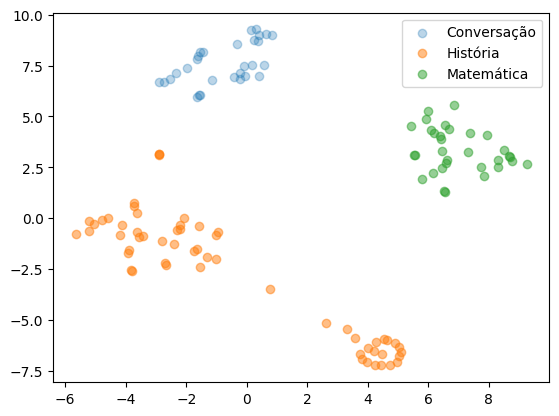

In [42]:
tsne = TSNE(n_components=2, random_state=42)
all_vectors_tsne = tsne.fit_transform(all_vectors)

plt.scatter(all_vectors_tsne[:len(vectors_conversation), 0], all_vectors_tsne[:len(vectors_conversation), 1], label="Conversação", alpha=0.3)

plt.scatter(all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 0], all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 1], label="História", alpha=0.5)
plt.scatter(all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 0], all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 1], label="Matemática", alpha=0.5)
plt.legend()
plt.show()

In [43]:
centroid_historia = np.mean(vectors_historia, axis=0)
centroid_matematica = np.mean(vectors_matematica, axis=0)

In [44]:
similarity_to_historia = cosine_similarity(vectors_conversation, centroid_historia.reshape(1, -1))
similarity_to_matematica = cosine_similarity(vectors_conversation, centroid_matematica.reshape(1, -1))
content_and_similarities = []
for i in range(len(chunks_conversation)):
    content_and_similarities.append({
        "chunk": chunks_conversation[i],
        "similarity_to_historia": similarity_to_historia[i, 0],
        "similarity_to_matematica": similarity_to_matematica[i, 0]
    })
df = pd.DataFrame(content_and_similarities)
df.sort_values(by="similarity_to_matematica", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
23,A conversa explora o impacto e a onipresença d...,0.341354,0.496302
21,A conversa gira em torno da interconexão da ma...,0.333430,0.495983
24,A conversa gira em torno do papel fascinante d...,0.325645,0.492753
27,A conversa explora o impacto da matemática na ...,0.342144,0.490347
22,A conversa explora a presença da matemática co...,0.342753,0.484820
26,A conversa gira em torno da matemática como um...,0.338766,0.480980
18,A conversa gira em torno do impacto duradouro ...,0.361067,0.479206
17,A conversa aborda as contribuições históricas ...,0.415436,0.476502
25,A conversa explora a interconexão entre matemá...,0.319885,0.469283
20,O resumo desta discussão se concentra na inter...,0.390522,0.464367


In [45]:
df.sort_values(by="similarity_to_historia", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
6,A conversa gira em torno das realizações impre...,0.487465,0.333158
8,A conversa explora a sofisticação das civiliza...,0.470325,0.358602
7,A conversa aborda os feitos avançados de civil...,0.458781,0.404149
9,A conversa gira em torno das contribuições das...,0.450397,0.386685
12,A conversa explorou as contribuições histórica...,0.450145,0.410307
10,A conversa foi centrada em história e matemáti...,0.449465,0.386904
4,A conversa entre as personas gira em torno da ...,0.448849,0.296571
13,A conversa destaca a interseção entre história...,0.440007,0.418485
0,A conversa aborda a admiração pela avançada cr...,0.434225,0.247362
3,A conversa gira em torno das civilizações anti...,0.432993,0.290525


In [46]:
example_matematica = df.sort_values(by="similarity_to_matematica", ascending=False).head(10)['chunk'].values
for x in example_matematica:
    print(x)

A conversa explora o impacto e a onipresença da matemática, destacando como conceitos numéricos, como o número pi e a proporção áurea, se manifestam em áreas diversas como arte, natureza e engenharia. Persona 1 e Persona 2 discutem como a matemática evoluiu de algo prático, como contagem e medição, para abstrações complexas que revolucionaram o pensamento humano, influenciaram avanços como computação teórica e inteligência artificial e permitiram entender fenômenos cósmicos, como na teoria da relatividade de Einstein. O diálogo reflete admiração pela interconexão entre matemática, natureza e o universo.
A conversa gira em torno da interconexão da matemática com a natureza e suas aplicações práticas e abstratas. Os participantes discutem a influência de matemáticos antigos como Euclides e Arquimedes, o impacto do número pi e da proporção áurea em diversas áreas como engenharia, arte e padrões naturais. Eles destacam como a matemática evoluiu de uma ferramenta prática para uma ciência al

In [47]:
example_historia = df.sort_values(by="similarity_to_historia", ascending=False).head(10)['chunk'].values
for x in example_historia:
    print(x)

A conversa gira em torno das realizações impressionantes das civilizações antigas, com foco principal na história e no avanço técnico e intelectual dessas culturas. Os participantes discutem a sofisticação dos egípcios, especialmente em astronomia, engenharia das pirâmides e hieróglifos, destacando a importância da Pedra de Roseta para decifrar a língua antiga. A discussão também aborda outras culturas, como os maias, que se destacaram por seu calendário avançado e pelo uso pioneiro do conceito de zero em matemática.
A conversa explora a sofisticação das civilizações antigas, especialmente os egípcios e seus avanços em astronomia, escrita e engenharia, como demonstrado na construção das pirâmides e o uso dos hieróglifos, decifrados graças à Pedra de Roseta. O diálogo segue para os maias e seu legado matemático, incluindo o calendário e o pioneirismo no uso do conceito de zero, relacionando isso às contribuições matemáticas de outras civilizações, como os babilônios, com seu sistema num

In [48]:
vectors_conversation

array([[ 7.17919916e-02,  8.55648052e-03,  6.96568331e-03, ...,
        -6.25748793e-03,  1.69861205e-02,  1.74723435e-02],
       [ 3.80773619e-02, -3.14332283e-05,  5.55509375e-03, ...,
        -2.61743255e-02,  2.03875545e-02,  1.03070419e-02],
       [ 7.20518455e-03, -5.64167800e-04, -7.96984229e-03, ...,
        -2.18331385e-02,  3.45898606e-02,  1.92718487e-02],
       ...,
       [ 3.60509492e-02,  1.09055657e-02,  3.98879014e-02, ...,
        -1.61069967e-02, -2.24805460e-03,  3.33630294e-02],
       [ 1.40388040e-02,  1.82464567e-03,  3.36612239e-02, ...,
        -7.54286582e-03, -1.44326477e-03,  2.73796562e-02],
       [ 2.47054938e-02,  1.16747916e-02,  4.08767238e-02, ...,
        -2.00196244e-02, -1.46857109e-02,  1.09868664e-02]],
      shape=(29, 1536))

In [49]:
sims_delta_s = []
cosine_similarities = []
for i in range(1, len(vectors_conversation)):
    delta = vectors_conversation[i] - vectors_conversation[i-1]
    delta_cos_sim = cosine_similarity(vectors_conversation[i].reshape(1, -1), vectors_conversation[i-1].reshape(1, -1))[0,0]
    sims_delta_s.append(delta)
    cosine_similarities.append(delta_cos_sim)
sims_delta_s = np.array(sims_delta_s)
cosine_similarities = np.array(cosine_similarities)

In [50]:
sims_delta_s.shape, cosine_similarities.shape

((28, 1536), (28,))

In [51]:
mods = np.linalg.norm(sims_delta_s, axis=1)
idxs_persona_1 = list(range(1, len(mods), 2))
idxs_persona_2 = list(range(0, len(mods), 2))

mods_persona_1 = mods[idxs_persona_1]
mods_persona_2 = mods[idxs_persona_2]

mods_cos_similarities_persona_1 = cosine_similarities[idxs_persona_1]
mods_cos_similarities_persona_2 = cosine_similarities[idxs_persona_2]

In [52]:
mods_persona_1.mean(), mods_persona_2.mean()

(np.float64(0.5255860744799491), np.float64(0.5351527924046025))

In [53]:
mods_cos_similarities_persona_1.mean(), mods_cos_similarities_persona_2.mean()

(np.float64(0.8540092819371026), np.float64(0.8498433193518269))

In [54]:
mods_cos_similarities_persona_1.std(), mods_cos_similarities_persona_2.std()

(np.float64(0.06700460610735053), np.float64(0.06351539772595938))